In [3]:
%pip install -q "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-nature==0.7.2" "pyscf==2.10.0"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for package in ["qiskit", "qiskit-algorithms", "qiskit-nature", "pyscf", "numpy", "scipy", "scikit-learn"]:
    print(package, version(package))
print("설치 완료: 다음 실행 코드 셀로 이동합니다.")

Python: 3.13.16
qiskit 2.2.3
qiskit-algorithms 0.4.0
qiskit-nature 0.7.2
pyscf 2.10.0
numpy 2.1.3
scipy 1.16.3
scikit-learn 1.6.1
설치 완료: 다음 실행 코드 셀로 이동합니다.


Running QAOA Scheduling Optimization...

Optimization Results & Verification
배정 행렬 (행: 작업1·2 / 열: 슬롯1·2):
 [[1 0]
 [0 1]]
제약 위반 수      : 0
완료 시점         : 2 슬롯
목적함수(벌점 포함): 2
유효 일정 관측 확률: 0.5103
검증 통과: QAOA가 완벽한 최적 생산 일정을 찾아냈습니다.


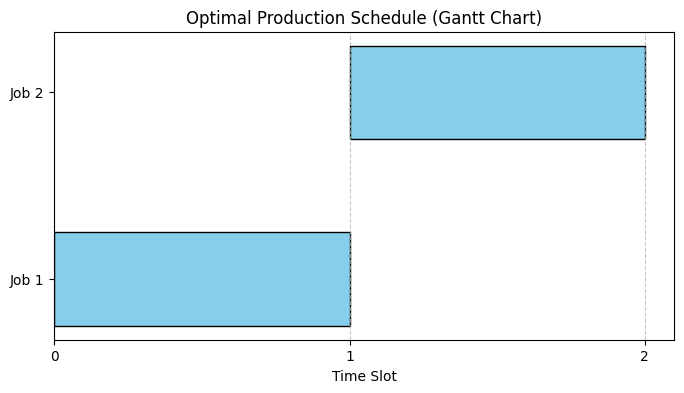

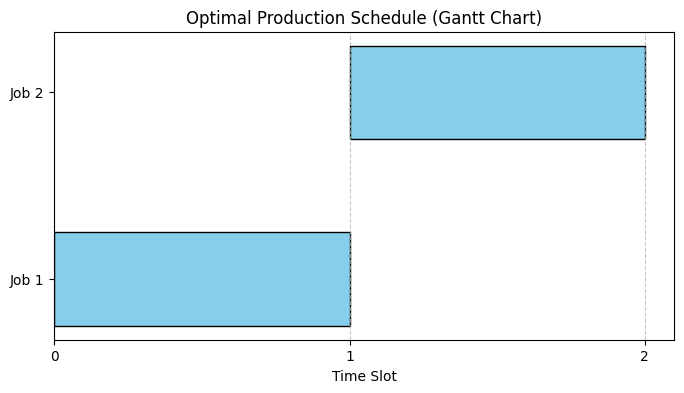

In [4]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from qiskit.quantum_info import SparsePauliOp, Operator
from qiskit.primitives import StatevectorSampler

from qiskit_algorithms import QAOA
from qiskit_algorithms.optimizers import COBYLA

import warnings
from scipy.sparse import SparseEfficiencyWarning
warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)


# ==============================================================================
# STEP 2. 생산 일정 제약 조건 및 목적 함수 정의
# ==============================================================================
# 4개의 비트(4큐비트)를 $2 \times 2$ 배정 행렬(행: 작업 1·2, 열: 슬롯 1·2)로 변환합니다.
def schedule(z):
    return np.array([(z >> q) & 1 for q in range(4)]).reshape(2, 2)

# 목적함수 = 완료 시점(Makespan) + 배정/충돌 위반 벌점(Penalty * 10)
def evaluate(z):
    x = schedule(z)
    # 제약 위반 계산: 각 작업이 정확히 1개의 슬롯에 배정되었는지 + 같은 슬롯에 두 작업이 겹치지 않는지
    violation = int(np.sum((x.sum(axis=1) - 1)**2) + sum(x[0, t] * x[1, t] for t in range(2)))
    # 완료 시점(Makespan) 계산
    occupied = np.flatnonzero(x.sum(axis=0))
    makespan = int(occupied[-1] + 1) if len(occupied) else 0
    return makespan + 10 * violation, violation, makespan


# ==============================================================================
# STEP 3. 모든 상태(16개)에 대한 비용 해밀턴산(Hamiltonian) 구성
# ==============================================================================
# 4큐비트가 표현할 수 있는 모든 경우의 수(16가지 상태)의 목적함수 값을 계산하고,
# 이를 대각 행렬 기반의 파울리 해밀턴산(H)으로 변환합니다.
values = np.array([evaluate(z)[0] for z in range(16)], dtype=float)
H = SparsePauliOp.from_operator(Operator(np.diag(values)))


# ==============================================================================
# STEP 4. QAOA 알고리즘 초기화 및 설정
# ==============================================================================
# - StatevectorSampler: 양자 측정 확률 분포를 샘플링
# - COBYLA: QAOA 파라미터(감마, 베타)를 조정하는 고전 최적화기
# - reps=2: QAOA 회로 레이어 반복 횟수
# - initial_point: 초기 감마/베타 각도 설정 [0.2, 0.4, 0.1, 0.3]
solver = QAOA(
    sampler=StatevectorSampler(default_shots=2048, seed=42),
    optimizer=COBYLA(maxiter=160),
    reps=2,
    initial_point=[0.2, 0.4, 0.1, 0.3]
)


# ==============================================================================
# STEP 5. QAOA 최적화 실행 (최적 파라미터 탐색)
# ==============================================================================
# 해밀턴산(H)을 입력하여 QAOA 최적화를 수행하고 결과 상태를 얻습니다.
print("=" * 60)
print("Running QAOA Scheduling Optimization...")
print("=" * 60)

result = solver.compute_minimum_eigenvalue(H)


# ==============================================================================
# STEP 6. 결과 분석, 제약 검증 및 최적 일정 추출
# ==============================================================================
# 측정된 결과에서 비트열 상태와 확률 분포 딕셔너리 생성
prob = {int(z, 2) if isinstance(z, str) else int(z): float(p) for z, p in result.eigenstate.items()}

# 제약 위반이 없는(violation == 0) 유효한 후보 일정들만 필터링
feasible = [int(z) for z, p in prob.items() if p > 0 and evaluate(int(z))[1] == 0]

# 유효한 후보 중 완료 시점(Makespan)이 가장 짧은 최적 일정 선택
best = min(feasible, key=lambda z: evaluate(z)[2])

print("\n" + "=" * 60)
print("Optimization Results & Verification")
print("=" * 60)
print("배정 행렬 (행: 작업1·2 / 열: 슬롯1·2):\n", schedule(best))
print("제약 위반 수      :", evaluate(best)[1])
print("완료 시점         :", evaluate(best)[2], "슬롯")
print("목적함수(벌점 포함):", evaluate(best)[0])
print("유효 일정 관측 확률:", round(sum(p for z, p in prob.items() if evaluate(int(z))[1] == 0), 4))

# 결과 검증
assert evaluate(best)[1:] == (0, 2), "일정 제약 위반 혹은 완료 시점이 잘못되었습니다!"
assert evaluate(best)[0] == values.min(), "최적 목적함수 값 도출 실패!"
print("검증 통과: QAOA가 완벽한 최적 생산 일정을 찾아냈습니다.")


# ==============================================================================
# STEP 7. 결과 시각화 (간트 차트, Gantt Chart)
# ==============================================================================
# 도출된 최적 배정 결과를 작업별 시간 슬롯 배정 형태의 가로 막대 그래프(간트 차트)로 시각화합니다.
fig, ax = plt.subplots(figsize=(8, 4))

for job, row in enumerate(schedule(best)):
    slot = int(np.argmax(row))
    ax.barh(job, 1, left=slot, color='skyblue', edgecolor='black', height=0.5)

ax.set_yticks([0, 1], labels=["Job 1", "Job 2"])
ax.set_xticks([0, 1, 2])
ax.set_xlabel("Time Slot")
ax.set_title("Optimal Production Schedule (Gantt Chart)")
ax.grid(axis='x', linestyle='--', alpha=0.7)

display(fig)
plt.show()